# 04 · AD vs CN from radiomics: whole brain vs data-driven ROI

**Radiomics** summarises an image region with a few dozen interpretable
statistics (pyradiomics):

| family | what it measures |
|---|---|
| first order | intensity distribution: mean, percentiles, entropy, skewness, ... |
| GLCM | co-occurrence of grey levels between neighbouring pixels (texture) |
| GLRLM / GLSZM | lengths of runs / sizes of zones with the same grey level |
| GLDM | dependence of each pixel on its neighbourhood |

We compare two masks in which the features are computed:

- **brain**: the whole brain mask;
- **ROI**: the PCA/ANOVA region of interest from notebook 02.

Both masks are fitted on the **training subjects only** (same 70/30 subject
split as notebook 03), and features are then extracted for every image.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from adni_tau.data import ImageLoader, split_subjects
from adni_tau.evaluation import fit_evaluate_binary, plot_confusion_matrices, results_table
from adni_tau.paths import PROCESSED_DIR, save_figure, save_table
from adni_tau.radiomics_features import RadiomicsExtractor, clean_feature_table
from adni_tau.roi import pca_roi

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
loader = ImageLoader(views=VIEWS, classes=["AD", "CN"])
data = {view: loader.load_view(view) for view in VIEWS}

y = data[VIEWS[0]]["classes"]
is_test = split_subjects(data[VIEWS[0]]["subject_ids"], y, test_size=0.3, random_state=42)

## 1. Masks (fitted on the training set)

   axial: brain 28343 px | ROI 2016 px from PCs [4, 1, 2]


 coronal: brain 26225 px | ROI 1637 px from PCs [4, 2, 3]


sagittal: brain 31345 px | ROI 1850 px from PCs [5, 2]


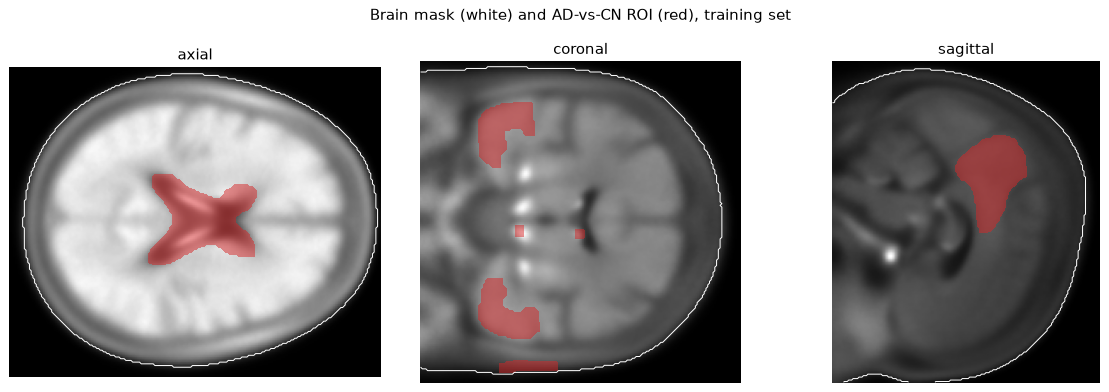

In [2]:
masks = {}
for view in VIEWS:
    d = data[view]
    roi = pca_roi(d["X"][~is_test], d["classes"][~is_test], d["shape"])
    masks[view] = {"brain": roi.brain_mask, "ROI": roi.roi}
    print(f"{view:>8}: brain {roi.brain_mask.sum()} px | ROI {roi.roi.sum()} px from PCs {[p + 1 for p in roi.selected_pcs]}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, view in zip(axes, VIEWS):
    d = data[view]
    ax.imshow(d["X"][~is_test].mean(axis=0).reshape(d["shape"]), cmap="gray")
    ax.contour(masks[view]["brain"], levels=[0.5], colors="white", linewidths=0.8)
    ax.contourf(masks[view]["ROI"], levels=[0.5, 1.5], colors=["tab:red"], alpha=0.5)
    ax.set_title(view)
    ax.axis("off")
fig.suptitle("Brain mask (white) and AD-vs-CN ROI (red), training set")
fig.tight_layout()
save_figure(fig, "04_masks_ad_cn")

## 2. Radiomics extraction

Extraction takes a few minutes, so features are cached in `data/processed/`
(git-ignored). Shape features are disabled: with one fixed mask per view they
would be identical for every subject.

In [3]:
extractor = RadiomicsExtractor()
features = {}
for view in VIEWS:
    for mask_name in ("brain", "ROI"):
        cache = PROCESSED_DIR / f"radiomics_ad_cn_{view}_{mask_name}.parquet"
        if cache.exists():
            df = pd.read_parquet(cache)
        else:
            d = data[view]
            images = (d["X"][i].reshape(d["shape"]) for i in range(len(d["X"])))
            df = extractor.extract_many(images, masks[view][mask_name], desc=f"{view}/{mask_name}")
            cache.parent.mkdir(parents=True, exist_ok=True)
            df.to_parquet(cache, index=False)
        features[(view, mask_name)] = df
print(f"{features[(VIEWS[0], 'brain')].shape[1]} radiomics features per image and mask")

88 radiomics features per image and mask


## 3. Classifiers

Four model families, each tuned by 5-fold CV on balanced accuracy:

- logistic regression and LDA after PCA (radiomics features are strongly
  correlated, so PCA acts as a decorrelating, regularising step);
- RBF SVM after PCA;
- random forest on the raw (cleaned) features.

In [4]:
def pca_pipe(clf):
    return Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=0)), ("clf", clf)])

MODELS = {
    "logistic regression": (pca_pipe(LogisticRegression(max_iter=5000, class_weight="balanced")), {"pca__n_components": [5, 10, 20], "clf__C": [0.01, 0.1, 1]}),
    "LDA": (pca_pipe(LinearDiscriminantAnalysis(solver="lsqr")), {"pca__n_components": [5, 10, 20], "clf__shrinkage": [None, "auto"]}),
    "RBF SVM": (pca_pipe(SVC(kernel="rbf", class_weight="balanced")), {"pca__n_components": [5, 10, 20], "clf__C": [0.1, 1, 10]}),
    "random forest": (
        Pipeline([("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=0, n_jobs=-1))]),
        {"clf__n_estimators": [300], "clf__max_depth": [None, 5], "clf__min_samples_leaf": [1, 5]},
    ),
}

rows, fitted = [], {}
for (view, mask_name), df in features.items():
    X_train = clean_feature_table(df[~is_test])
    X_test = clean_feature_table(df[is_test], reference=df[~is_test])
    for model_name, (pipe, grid) in MODELS.items():
        res = fit_evaluate_binary(X_train.to_numpy(), y[~is_test], X_test.to_numpy(), y[is_test], pipe, grid, positive_label="AD")
        fitted[(view, mask_name, model_name)] = res
        rows.append({"view": view, "mask": mask_name, "model": model_name, "cv_balanced_accuracy": res["cv_score"], "metrics": res["metrics"]})

results = results_table(rows)
save_table(results, "04_radiomics_ad_cn_results")
results.round(3)

,view,mask,model,cv_balanced_accuracy,accuracy,balanced_accuracy,macro_f1,roc_auc
0,axial,brain,logistic regression,0.782,0.842,0.830,0.750,0.893
1,axial,brain,LDA,0.733,0.887,0.674,0.713,0.891
2,axial,brain,RBF SVM,0.785,0.770,0.710,0.648,0.805
3,axial,brain,random forest,0.775,0.883,0.711,0.734,0.850
4,axial,ROI,logistic regression,0.763,0.752,0.660,0.614,0.748
5,axial,ROI,LDA,0.714,0.838,0.593,0.608,0.726
6,axial,ROI,RBF SVM,0.739,0.770,0.658,0.622,0.739
7,axial,ROI,random forest,0.716,0.820,0.648,0.644,0.752
8,coronal,brain,logistic regression,0.782,0.842,0.830,0.750,0.916
9,coronal,brain,LDA,0.754,0.914,0.742,0.790,0.926


## 4. Results

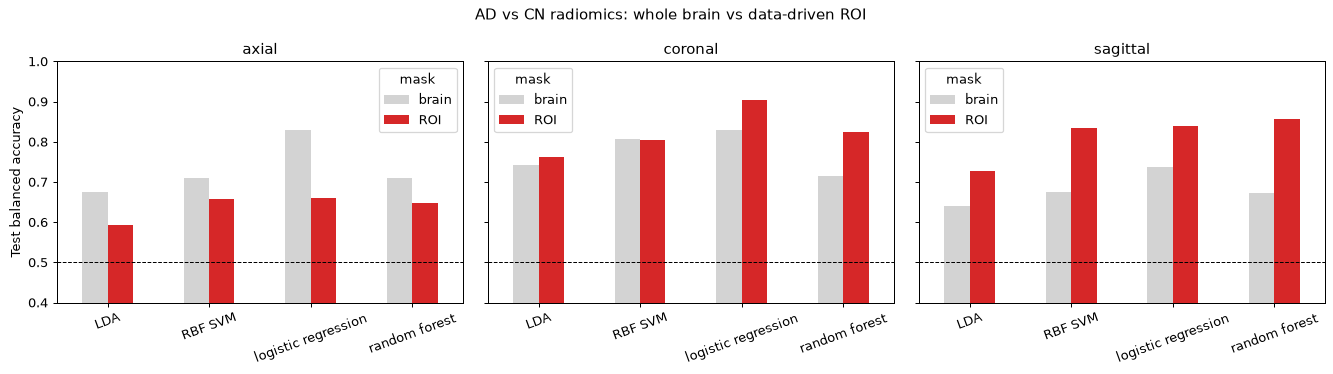

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, view in zip(axes, VIEWS):
    sub = results[results["view"] == view].pivot(index="model", columns="mask", values="balanced_accuracy")[["brain", "ROI"]]
    sub.plot.bar(ax=ax, rot=20, color=["lightgray", "tab:red"])
    ax.axhline(0.5, color="k", linestyle="--", linewidth=0.8)
    ax.set(title=view, ylim=(0.4, 1), xlabel="", ylabel="Test balanced accuracy")
fig.suptitle("AD vs CN radiomics: whole brain vs data-driven ROI")
fig.tight_layout()
save_figure(fig, "04_radiomics_brain_vs_roi")

In [6]:
summary = results.groupby("mask")[["balanced_accuracy", "roc_auc", "macro_f1"]].agg(["mean", "max"]).round(3)
summary

balanced_accuracy        roc_auc        macro_f1       
                   mean    max    mean    max     mean    max
mask                                                         
ROI               0.759  0.903   0.864  0.948    0.744  0.838
brain             0.729  0.830   0.849  0.926    0.712  0.790

**Reading the results.**

- **The ROI helps where it captures tau.** In the coronal view (medial
  temporal lobes) and the sagittal view (parietal cortex), restricting the
  radiomics to the ROI improves 7 of the 8 models (the coronal SVM is
  unchanged). The best result of the project
  is **coronal ROI + logistic regression: balanced accuracy 0.90, ROC-AUC
  0.95**.
- **In the axial view the ROI hurts.** That ROI is the lateral ventricles
  (see notebook 02), an indirect atrophy marker with little tracer signal,
  so the whole-brain features are better there.
- **Radiomics in the ROI beats raw pixels** (best pixel model: 0.85 balanced
  accuracy) with only 88 interpretable features instead of ~30,000 pixels.

Best: logistic regression on coronal / ROI - balanced accuracy 0.903, ROC-AUC 0.948


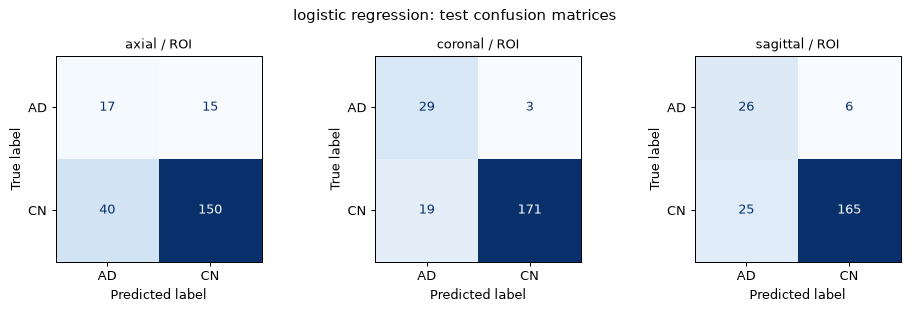

In [7]:
best = results.sort_values("balanced_accuracy", ascending=False).iloc[0]
print(f"Best: {best['model']} on {best['view']} / {best['mask']} - balanced accuracy {best['balanced_accuracy']:.3f}, ROC-AUC {best['roc_auc']:.3f}")
fig = plot_confusion_matrices({f"{v} / {best['mask']}": fitted[(v, best["mask"], best["model"])] for v in VIEWS}, title=f"{best['model']}: test confusion matrices")
save_figure(fig, "04_radiomics_confusion")

## 5. Which radiomics features matter?

Univariate view: for each feature computed in the ROI, the standardised
mean difference (Cohen's *d*) between AD and CN on the training set.

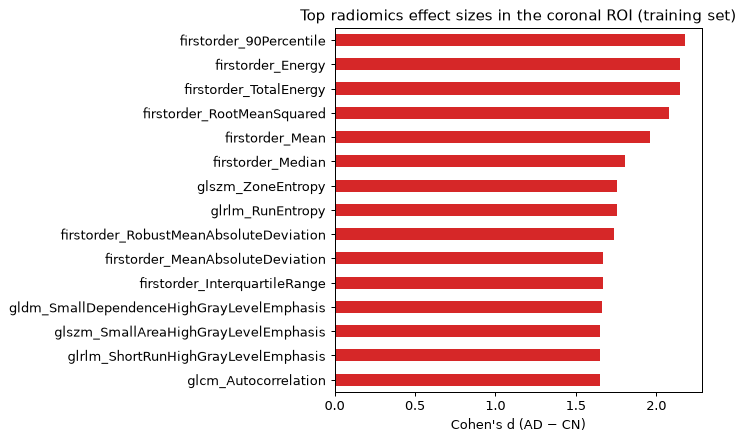

In [8]:
view = "coronal"
df = clean_feature_table(features[(view, "ROI")][~is_test])
ytr = y[~is_test]
ad, cn = df[ytr == "AD"], df[ytr == "CN"]
pooled = np.sqrt(((len(ad) - 1) * ad.var() + (len(cn) - 1) * cn.var()) / (len(ad) + len(cn) - 2))
d_eff = ((ad.mean() - cn.mean()) / pooled).dropna()
top = d_eff.reindex(d_eff.abs().sort_values(ascending=False).index)[:15]
top.index = [i.replace("original_", "") for i in top.index]

fig, ax = plt.subplots(figsize=(8, 5))
top[::-1].plot.barh(ax=ax, color=np.where(top[::-1] > 0, "tab:red", "tab:blue"))
ax.set(xlabel="Cohen's d (AD − CN)", title=f"Top radiomics effect sizes in the {view} ROI (training set)")
fig.tight_layout()
save_figure(fig, "04_radiomics_effect_sizes")

**Reading the effect sizes.** The most discriminative features are simple
**intensity statistics** (90th percentile, mean, energy) with very large
effects (Cohen's *d* ≈ 2): AD subjects have much higher tau uptake in the
temporal ROI. Texture features describing **heterogeneity** (zone and run
entropy, high-grey-level emphasis) follow closely: tau deposits are
patchier in AD.